# 🍰 Meu Docin — Análise de Vendas com Python

Neste notebook uso **Python (pandas e matplotlib)** para responder as mesmas perguntas do dashboard que fiz no **Power BI** com os mesmos dados:

- Quanto a confeitaria faturou e como isso se compara ao mês anterior?
- Quais dias da semana vendem mais?
- Quais são os produtos e as categorias campeões?
- Como o canal online evolui e como os clientes pagam no balcão?

> ⚠️ **Projeto de portfólio com dados 100% fictícios.**

## 1. Importar as bibliotecas

- `pandas`: ler e analisar tabelas
- `matplotlib`: criar gráficos

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 2. Ler os dados

O arquivo CSV usa `;` como separador e vírgula nos decimais (padrão brasileiro). Cada linha é **um item vendido**.

In [2]:
df = pd.read_csv("base_vendas_meu_docin.csv", sep=";", decimal=",", encoding="utf-8-sig")

print(df.shape[0], "linhas e", df.shape[1], "colunas")
df.head()

6764 linhas e 11 colunas


,ID_Venda,Data,Hora,Canal,Cod_Produto,Produto,Categoria,Quantidade,Preco_Unitario,Valor_Total_Item,Forma_Pagamento
0,10001,01/08/2026,10:30:16,Presencial,P01,Merengue de Morango (copo),Sobremesas,3,22.99,68.97,Crédito
1,10001,01/08/2026,10:30:16,Presencial,P10,Bolo de Chocolate com cobertura (fatia),Bolos,1,10.99,10.99,Crédito
2,10002,01/08/2026,10:36:18,Presencial,P06,Brownie com sorvete,Brownies,2,26.99,53.98,PIX
3,10002,01/08/2026,10:36:18,Presencial,P10,Bolo de Chocolate com cobertura (fatia),Bolos,2,10.99,21.98,PIX
4,10002,01/08/2026,10:36:18,Presencial,P12,Bolo de Ninho (fatia),Bolos,2,14.99,29.98,PIX


## 3. Preparar os dados

Duas coisas para facilitar a análise:
1. Transformar a coluna `Data` (que veio como texto) em data de verdade.
2. Criar as colunas `Mes` e `Dia_Semana`.

In [3]:
# Texto -> data
df["Data"] = pd.to_datetime(df["Data"], format="%d/%m/%Y")

# Número do mês (8 = agosto, 9 = setembro, 10 = outubro)
df["Mes"] = df["Data"].dt.month

# Dia da semana (o Python conta segunda = 0 ... domingo = 6)
nomes_dias = {0: "SEG", 1: "TER", 2: "QUA", 3: "QUI", 4: "SEX", 5: "SÁB", 6: "DOM"}
df["Dia_Semana"] = df["Data"].dt.dayofweek.map(nomes_dias)

df[["Data", "Mes", "Dia_Semana"]].head()

C:\Users\Pichau\AppData\Local\Temp\ipykernel_7512\618044141.py:9: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["Dia_Semana"] = df["Data"].dt.dayofweek.map(nomes_dias)


,Data,Mes,Dia_Semana
0,2026-08-01,8,SÁB
1,2026-08-01,8,SÁB
2,2026-08-01,8,SÁB
3,2026-08-01,8,SÁB
4,2026-08-01,8,SÁB


## 4. Indicadores por mês (os cartões do dashboard)

Com `groupby` calculo, para cada mês: faturamento, produtos vendidos, número de vendas e ticket médio (faturamento ÷ número de vendas). Depois comparo cada mês com o anterior.

In [4]:
resumo = df.groupby("Mes").agg(
    faturamento=("Valor_Total_Item", "sum"),
    produtos_vendidos=("Quantidade", "sum"),
    vendas=("ID_Venda", "nunique"),   # nunique = conta vendas sem repetir
)

resumo["ticket_medio"] = resumo["faturamento"] / resumo["vendas"]

# % do faturamento que veio do canal online
fat_online = df[df["Canal"] == "Online"].groupby("Mes")["Valor_Total_Item"].sum()
resumo["pct_online"] = fat_online / resumo["faturamento"] * 100

# Variação do faturamento em relação ao mês anterior
resumo["variacao_faturamento_%"] = resumo["faturamento"].pct_change() * 100

resumo.round(2)

,faturamento,produtos_vendidos,vendas,ticket_medio,pct_online,variacao_faturamento_%
Mes,,,,,,
8,62639.31,3669,1067,58.71,36.53,NaN
9,53811.33,3167,961,56.00,36.40,-14.09
10,72074.28,4172,1240,58.12,38.97,33.94


## 5. Análises de outubro

A partir daqui uso só o mês de **outubro**, o mês de referência do dashboard.

In [5]:
outubro = df[df["Mes"] == 10]

### 5.1 Faturamento por dia da semana

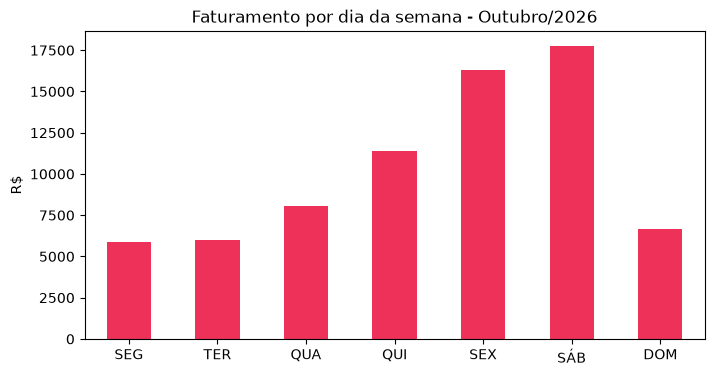

In [6]:
ordem_dias = ["SEG", "TER", "QUA", "QUI", "SEX", "SÁB", "DOM"]

por_dia = outubro.groupby("Dia_Semana")["Valor_Total_Item"].sum().reindex(ordem_dias)

por_dia.plot(kind="bar", color="#ED3158", figsize=(8, 4), title="Faturamento por dia da semana - Outubro/2026")
plt.xlabel("")
plt.ylabel("R$")
plt.xticks(rotation=0)
plt.show()

### 5.2 Top 5 produtos mais vendidos (em quantidade)

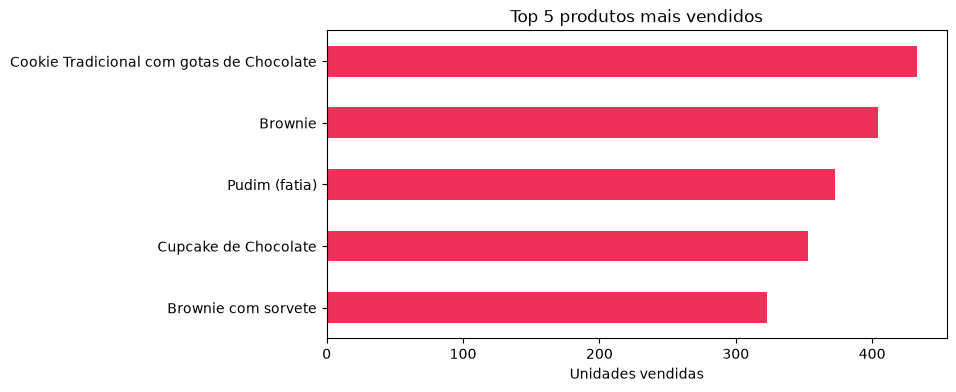

In [7]:
top5 = outubro.groupby("Produto")["Quantidade"].sum().nlargest(5).sort_values()

top5.plot(kind="barh", color="#ED3158", figsize=(8, 4), title="Top 5 produtos mais vendidos")
plt.xlabel("Unidades vendidas")
plt.ylabel("")
plt.show()

### 5.3 Faturamento por categoria

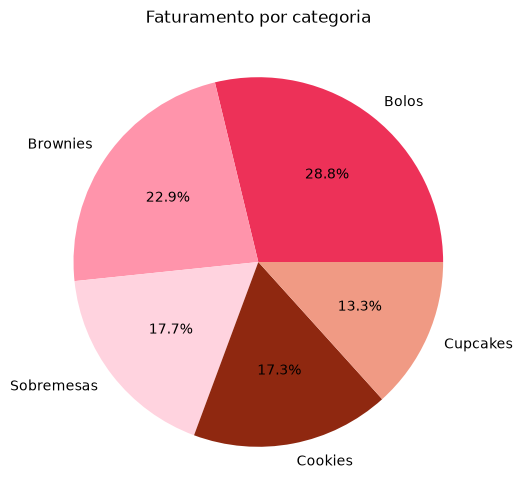

In [8]:
por_categoria = outubro.groupby("Categoria")["Valor_Total_Item"].sum().sort_values(ascending=False)

cores = ["#ED3158", "#FF94AB", "#FFD3DF", "#8F2810", "#F09A84"]
por_categoria.plot(kind="pie", autopct="%1.1f%%", colors=cores, figsize=(6, 6), title="Faturamento por categoria")
plt.ylabel("")
plt.show()

### 5.4 Faturamento por mês e canal (Online × Presencial)

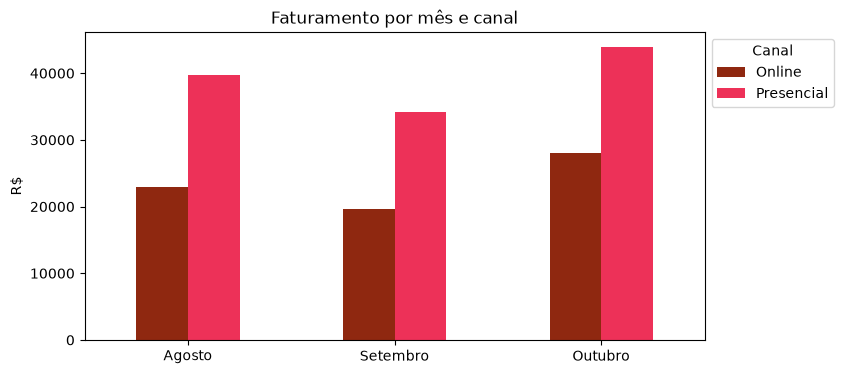

In [9]:
canal_mes = df.groupby(["Mes", "Canal"])["Valor_Total_Item"].sum().unstack()
canal_mes = canal_mes.rename(index={8: "Agosto", 9: "Setembro", 10: "Outubro"})

canal_mes.plot(kind="bar", color=["#8F2810", "#ED3158"], figsize=(8, 4), title="Faturamento por mês e canal")
plt.xlabel("")
plt.ylabel("R$")
plt.xticks(rotation=0)
plt.legend(title="Canal", loc="upper left", bbox_to_anchor=(1, 1))   # legenda fora do gráfico
plt.show()

### 5.5 Forma de pagamento no presencial

In [10]:
presencial = outubro[outubro["Canal"] == "Presencial"]

pagamento = presencial.groupby("Forma_Pagamento")["Valor_Total_Item"].sum()
pagamento_pct = (pagamento / pagamento.sum() * 100).sort_values(ascending=False)

pagamento_pct.round(2)

Forma_Pagamento
PIX         43.41
Crédito     24.78
Débito      21.76
Dinheiro    10.05
Name: Valor_Total_Item, dtype: float64

### 5.6 Faturamento por produto e dia da semana

Mesma ideia da matriz do Power BI, feita com `pivot_table`.

In [11]:
matriz = outubro.pivot_table(
    index=["Categoria", "Produto"],
    columns="Dia_Semana",
    values="Valor_Total_Item",
    aggfunc="sum",
    margins=True,
    margins_name="Total",
)

matriz = matriz[ordem_dias + ["Total"]]   # coloca os dias na ordem certa
matriz.round(2)

Dia_Semana                                                         SEG  \
Categoria  Produto                                                       
Bolos      Bolo de Cenoura com cobertura de Chocolate (fatia)   302.75   
           Bolo de Chocolate com cobertura (fatia)              368.69   
           Bolo de Chocolate sem cobertura (fatia)              147.86   
           Bolo de Laranja (fatia)                              124.87   
           Bolo de Ninho (fatia)                                428.75   
           Bolo de Ninho com Morango (fatia)                    241.87   
Brownies   Brownie                                              440.75   
           Brownie com sorvete                                  733.78   
Cookies    Cookie Tradicional com gotas de Chocolate            550.62   
           Cookie Trufado de Chocolate                          724.67   
Cupcakes   Cupcake de Chocolate                                 482.69   
           Cupcake de Coco                                      341.80   
Sobremesas Merengue de Morango (copo)                           581.79   
           Pudim (fatia)                                        424.70   
Total                                                          5895.59   

Dia_Semana                                                         TER  \
Categoria  Produto                                                       
Bolos      Bolo de Cenoura com cobertura de Chocolate (fatia)   298.75   
           Bolo de Chocolate com cobertura (fatia)              380.69   
           Bolo de Chocolate sem cobertura (fatia)              211.80   
           Bolo de Laranja (fatia)                               56.95   
           Bolo de Ninho (fatia)                                398.75   
           Bolo de Ninho com Morango (fatia)                    534.71   
Brownies   Brownie                                              509.70   
           Brownie com sorvete                                  697.76   
Cookies    Cookie Tradicional com gotas de Chocolate            575.57   
           Cookie Trufado de Chocolate                          451.81   
Cupcakes   Cupcake de Chocolate                                 575.66   
           Cupcake de Coco                                      380.77   
Sobremesas Merengue de Morango (copo)                           504.80   
           Pudim (fatia)                                        421.71   
Total                                                          5999.43   

Dia_Semana                                                         QUA  \
Categoria  Produto                                                       
Bolos      Bolo de Cenoura com cobertura de Chocolate (fatia)   495.60   
           Bolo de Chocolate com cobertura (fatia)              258.79   
           Bolo de Chocolate sem cobertura (fatia)              147.86   
           Bolo de Laranja (fatia)                              256.75   
           Bolo de Ninho (fatia)                                263.84   
           Bolo de Ninho com Morango (fatia)                    586.70   
Brownies   Brownie                                              638.61   
           Brownie com sorvete                                  700.77   
Cookies    Cookie Tradicional com gotas de Chocolate            865.37   
           Cookie Trufado de Chocolate                         1013.54   
Cupcakes   Cupcake de Chocolate                                 593.66   
           Cupcake de Coco                                      638.65   
Sobremesas Merengue de Morango (copo)                           819.71   
           Pudim (fatia)                                        759.50   
Total                                                          8039.35   

Dia_Semana                                                          QUI  \
Categoria  Produto                                                        
Bolos      Bolo de Cenoura com cobertura de Chocolate (fatia)    546.55  

## 6. Conferindo com o Power BI

Para garantir que a análise em Python está correta, comparo alguns números com os que aparecem no dashboard.

In [12]:
faturamento_out = round(outubro["Valor_Total_Item"].sum(), 2)
produtos_out = outubro["Quantidade"].sum()
ticket_out = round(faturamento_out / outubro["ID_Venda"].nunique(), 2)

print("Faturamento:", faturamento_out, "| Power BI: 72074.28")
print("Produtos vendidos:", produtos_out, "| Power BI: 4172")
print("Ticket médio:", ticket_out, "| Power BI: 58.12")

assert faturamento_out == 72074.28
assert produtos_out == 4172
assert ticket_out == 58.12
print("✅ Os números batem com o Power BI!")

Faturamento: 72074.28 | Power BI: 72074.28
Produtos vendidos: 4172 | Power BI: 4172
Ticket médio: 58.12 | Power BI: 58.12
✅ Os números batem com o Power BI!


## 7. Conclusões (outubro/2026)

- **Fim de semana forte:** sexta e sábado somam cerca de **47%** do faturamento do mês.
- **Bolos** são a categoria que mais fatura (≈ **28,8%**), mas o **Cookie Tradicional** é o produto mais vendido em unidades.
- **Canal online ganhando força:** passou de **36,4%** do faturamento em setembro para **38,97%** em outubro.
- **PIX** é a forma de pagamento preferida no balcão (**43,41%**).

---
*Dados fictícios, criados para estudo e demonstração.*